verinin yerini pythona söyledik

In [1]:
from pathlib import Path
from collections import defaultdict
DATA_DIR=Path("../data/NEU-DET")
IMG_DIR=DATA_DIR/"IMAGES"
ANN_DIR=DATA_DIR/"ANNOTATIONS"
images=sorted(IMG_DIR.glob("*.jpg"))
print("görüntü sayısı:",len(images))
print("ilk 3",[p.name for  p in images[:3]])

görüntü sayısı: 1800
ilk 3 ['crazing_1.jpg', 'crazing_10.jpg', 'crazing_100.jpg']


her resmin adından hata türünü cikaran bir fonksiyon yazdım

In [2]:
from collections import Counter
def class_from_name(path):
     # "rolled-in_scale_12.jpg" -> "rolled-in_scale"
    return path.stem.rsplit("_",1)[0]#path stem uzantıyı kaldrırı rsplit  ayiriyor alt cizgi karakterinden  1 kez ayirdi
counts = Counter(class_from_name(p) for p in images)
for cls,n in sorted(counts.items()):
    print(f"{cls:20s} {n}")

crazing              300
inclusion            300
patches              300
pitted_surface       300
rolled-in_scale      300
scratches            300


her hatadan resimlere baktık tam olarak hata neye benziyor diye

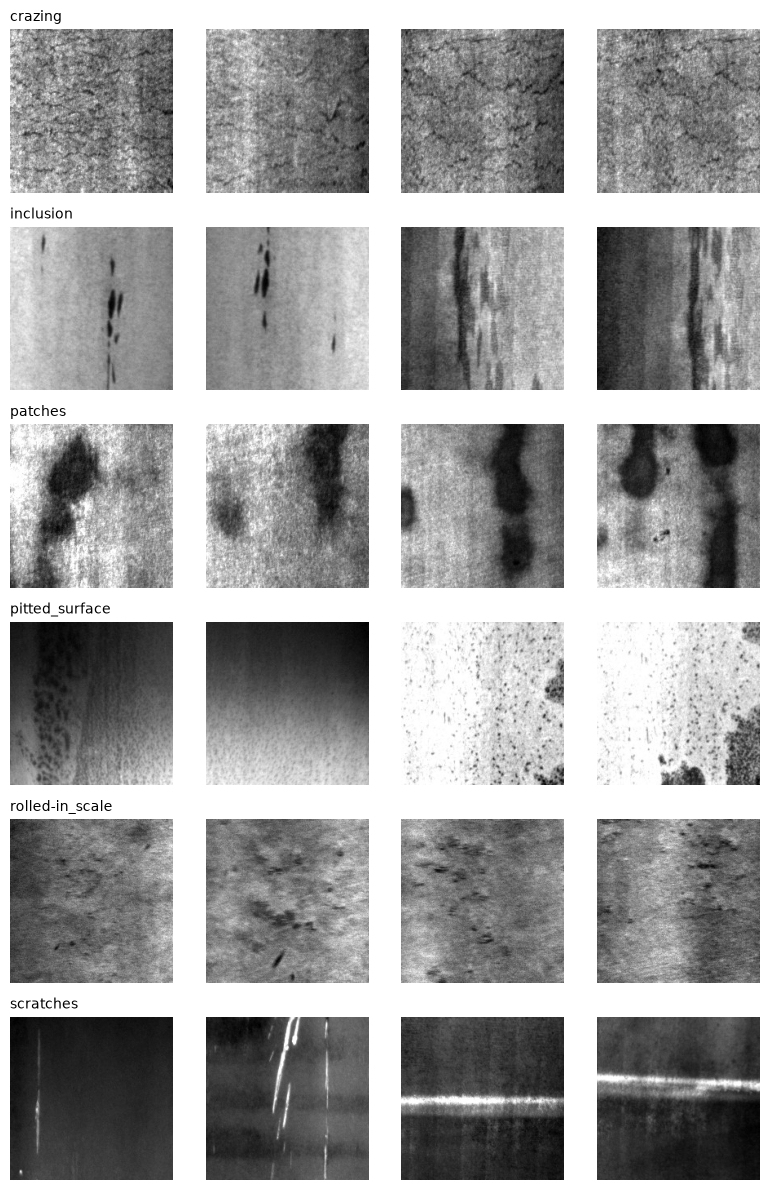

In [3]:
import matplotlib.pyplot as plt 
import cv2
classes=sorted(counts)
fig,axes=plt.subplots(len(classes),4,figsize=(8,12))
for row ,cls in enumerate(classes):
    cls_images=[p for p in images if class_from_name(p)==cls][:4]
    for col,p in enumerate(cls_images):
        img=cv2.imread(str(p),cv2.IMREAD_GRAYSCALE)
        axes[row,col].imshow(img,cmap="gray")
        axes[row,col].axis("off")
        axes[row,0].set_title(cls,loc="left",fontsize=10)
plt.tight_layout()
fig.savefig("../reports/figures/01_class_samples.png", dpi=150)
plt.show()

scratches ve patches karişmaz knedine özgü sekilleri var  crazing roll_in_scale karişabilir Crazing’de izler ince ve dalgalı çatlaklar şeklinde. Rolled-in_scale’de ise küçük koyu pullar var nclusion ↔ pitted_surface: İkisinde de koyu noktalar ya da benekler var. Inclusion’daki lekeler uzun ve dikey yönde. Pitted_surface’de ise dağınık küçük noktalar var. ayrıca aynı sınıfta büyük farklılıklar var


burda kutunun mantıgını anlamak için kendim kutuya tekrar etiket oluşturdum

kutu 26 12 43 171


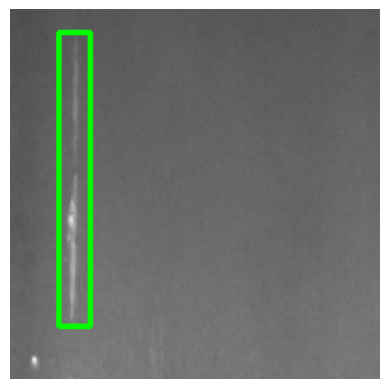

In [4]:
import matplotlib.pyplot as plt
import cv2
img = cv2.imread(str(IMG_DIR/"scratches_1.jpg"))
#xml den okudugumuz kutuyu elle yazıyoruz
import xml.etree.ElementTree as ET
root=ET.parse(ANN_DIR/"scratches_1.xml").getroot()
box=root.find("object").find("bndbox")
xmin=int(box.find("xmin").text)
ymin=int(box.find("ymin").text)
xmax=int(box.find("xmax").text)
ymax=int(box.find("ymax").text)
print("kutu",xmin,ymin,xmax,ymax)
cv2.rectangle(img,(xmin,ymin),(xmax,ymax),(0,255,0),2)
plt.imshow(img)
plt.axis("off")
plt.show()



4189 tane kutu var resim başına 2 3 hata var 

In [5]:
import xml.etree.ElementTree as ET
import pandas as pd
def parse_xml(xml_path):
    root=ET.parse(xml_path).getroot()
    filename=root.find("filename").text
    rows=[]
    for obj in root.findall("object"):
        box=obj.find("bndbox")
        rows.append({
            "file":filename,
            "class":obj.find("name").text,
            "xmin":int(box.find("xmin").text),
            "ymin":int(box.find("ymin").text),
            "xmax":int(box.find("xmax").text),
            "ymax":int(box.find("ymax").text)
        })
    return rows
all_rows=[]
for xml_path in sorted(ANN_DIR.glob("*.xml")):
    all_rows.extend(parse_xml(xml_path))
df=pd.DataFrame(all_rows)
print("toplam kutu:",len(df))
df.head()

toplam kutu: 4189


,file,class,xmin,ymin,xmax,ymax
0,crazing_1.jpg,crazing,2,2,193,194
1,crazing_10.jpg,crazing,60,20,194,69
2,crazing_10.jpg,crazing,9,84,197,198
3,crazing_100.jpg,crazing,1,10,108,121
4,crazing_100.jpg,crazing,35,1,200,83


 Her kutunun genişliğini, yüksekliğini, şeklini (genişlik/yükseklik) ve resmin ne kadarını kapladığını hesapladık. Sonra her sınıfın ortalamasını aldık.

In [6]:
df["width"] = df["xmax"] - df["xmin"]
df["height"] = df["ymax"] - df["ymin"]
df["aspect"] = df["width"] / df["height"]
df["area_ratio"] = (df["width"] * df["height"]) / (200 * 200)

df.groupby("class")[["width", "height", "aspect", "area_ratio"]].mean().round(2)


,width,height,aspect,area_ratio
class,,,,
crazing,125.15,75.35,1.89,0.23
inclusion,28.51,85.10,0.45,0.07
patches,56.24,83.37,0.83,0.13
pitted_surface,127.34,172.97,0.77,0.57
rolled-in_scale,73.07,77.81,1.13,0.15
scratches,61.33,114.98,2.21,0.09


üst hücrede hatanın boyutunu ve şeklini analiz ettik

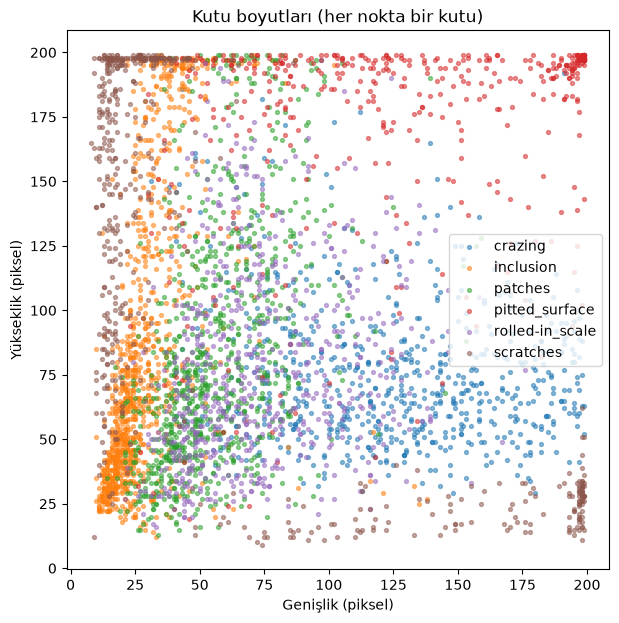

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
for cls in classes:
    sub = df[df["class"] == cls]
    ax.scatter(sub["width"], sub["height"], s=8, alpha=0.5, label=cls)

ax.set_xlabel("Genişlik (piksel)")
ax.set_ylabel("Yükseklik (piksel)")
ax.set_title("Kutu boyutları (her nokta bir kutu)")
ax.legend()
fig.savefig("../reports/figures/02_box_sizes.png", dpi=150)
plt.show()